# Phase 3: Unpaired translation models

We trained a CycleGAN to translate between single-cell pseudobulk and whole-blood bulk profiles without any matched pairs, from the single-cell profiles of 33 training donors and the bulk profiles of 35 others (M1, strictly unpaired), and the same model with an added composition loss through composition networks trained on pairs (M2, weakly paired). We selected both on 135 validation pairs from 14 donors by their margin beyond the unpaired accuracy–realism frontier, the best realism that blends of simple unpaired baselines reach at each accuracy. The chosen M1 reaches the frontier but does not clearly pass it: its validation margin is +0.056 (SD 0.041 over 3 seeds) in single-cell → bulk and −0.012 (SD 0.031) in bulk → single-cell, and without checkpoint selection it lies inside the frontier in both directions (mean over the last quarter of training −0.023 and −0.057). Composition supervision raises composition R² under an independent marker probe by 0.189 (95% donor-bootstrap CI 0.136–0.293) in single-cell → bulk and by 0.273 (95% CI 0.155–0.511) in bulk → single-cell, repairing composition that adversarial training loses, but not beyond the unpaired ComBat baseline (0.587 against 0.570 in single-cell → bulk, 0.206 against 0.333 in bulk → single-cell). The composition networks behind this supervision had seen the training donors' pairs, so pair information entered through both task terms. The paired reference, ridge + spread, is about as realistic as the unpaired models and far more accurate (centered R² 0.126 and 0.224, against −0.263 and −0.188 for M1). These are validation results; the hypotheses are tested once, on the test donors, in Phase 7.

## 1. Aim

Can a cycle-consistent adversarial translator learn to map single-cell pseudobulk profiles to whole-blood bulk profiles and back without ever seeing a matched pair, and does it reach a better trade-off between accuracy and realism than unpaired methods give for free? We trained the strictly unpaired model (M1) and the weakly paired model (M2, which adds composition supervision derived from pairs), selected them on validation by pre-specified rules, and compared them with the unpaired frontier of Phase 1. The claims themselves are tested once, on the test donors, in Phase 7.

## 2. Data

- **Training: halving 0 of the training split** (582 pairs, 68 donors; Phase 0). A halving divides the training donors into two donor-disjoint halves, A and B (Phase 1, §3.5). The models saw the single-cell pseudobulk profiles of half A (33 donors, 288 draws) and the whole-blood bulk profiles of half B (35 donors, 294 draws). No pair was seen in training, and the training code rejects any row outside these halves. As a sensitivity check, the chosen settings were also trained on halving 1, a second division that shares 19 of its 33 half-A donors with halving 0.
- **Weakly paired model only:** the measured composition $c^*$ of half A's single-cell samples, and the frozen composition networks $C_B$ (bulk) and $C_S$ (single-cell) of Phase 2. $C_B$ was trained on pairs, which is what makes M2 weakly paired.
- **Selection and reporting: validation** (135 pairs, 14 donors). Every translation was scored by the Phase 1 evaluators, fit on the training targets, against the unpaired frontier of the same halving (Phase 1, §3.8). The test split (119 pairs, 14 donors) is not used.

## 3. Methods

**Notation and metrics** (defined in full in Phase 1, §3). $x_S$ and $x_B$ are single-cell pseudobulk and whole-blood bulk profiles (log(1 + CP10k) on the 5,000-gene panel), $G_{S\to B}$ and $G_{B\to S}$ the two generators, and $c^*$ the measured composition over six cell-type classes. For a translation $\hat y$ of a validation source whose real partner is $y$:

- **Centered R²** (accuracy): $1 - \lVert \hat y - y\rVert^2 / \lVert y - \mu\rVert^2$, with $\mu$ the per-gene training mean of the target domain, reported as the median over validation draws. 0 is no better than predicting the training mean; higher is better.
- **Realism**: $1 - 2\,\lvert \text{AUROC} - 0.5 \rvert$, where the AUROC is that of a classifier two-sample test (C2ST; Lopez-Paz and Oquab, 2017): a logistic regression, cross-validated in folds grouped by donor, that separates translated from real validation targets on their top 10 principal-component scores and their squares. 1 means indistinguishable, 0 perfectly separable.
- **Unpaired frontier and margin**: the frontier $F(r)$ is the highest realism reached, at centered R² of at least $r$, by any blend of two of mean shift, ComBat (Johnson et al., 2007), CORAL (Sun et al., 2016) and the training-target mean, all fit on the same training halves. A model at accuracy $r$ and realism $s$ has margin $s - F(r)$; a positive margin means that no blend of unpaired baselines is as realistic at that accuracy. If no blend is as accurate as the model, the margin is the model's accuracy lead over the most accurate blend.
- **Composition R²**: the mean over the six classes of the per-class R² of a composition readout of the translation against $c^*$. The **ridge probe** reads composition from all 5,000 genes by ridge regression fit on training targets. The **marker probe** is a ridge regression on 28 lineage marker genes (Phase 2), independent of the composition networks that M2 trains against.
- **Within-donor top-1 rate**: the share of validation sources whose translation is closest to the true partner among that donor's draws (chance 0.104). **Diversity ratio**: the mean pairwise distance among translations over that among real targets (1 = as diverse as real). **Granulocyte gap** (single-cell → bulk only): the mean translated minus real expression of the panel's granulocyte genes, which profiles derived from peripheral blood mononuclear cells (PBMCs) lack.
- **Uncertainty**: the SD over 3 seeds, or a paired 95% CI from 1,000 bootstrap resamples of the 14 validation donors.

### 3.1 Models

Each direction has a generator and a discriminator:

| Network | Architecture | Normalization and activation |
|---|---|---|
| Generators $G_{S\to B}$, $G_{B\to S}$ | $G(x) = \mathrm{ReLU}\big(a \odot x + f(x)\big)$, with a learnable per-gene scale $a$ and a residual multilayer perceptron $f$: 5,000 → 512 → 512 → 5,000 | LayerNorm and LeakyReLU(0.2) after each hidden layer |
| Discriminators $D_B$, $D_S$ | multilayer perceptron 5,000 → 256 → 64 → 1 | spectral normalization, LeakyReLU(0.2) |

The last layer of $f$ starts at zero weights, so each generator starts exactly at an affine map $x \mapsto a \odot x + b$: single-cell → bulk at mean shift ($a = 1$, $b$ the per-gene difference of the halves' means) and bulk → single-cell at ComBat fit on the halves, the most accurate unpaired baseline in each direction (Phase 1).

The generators minimize the least-squares adversarial loss (Mao et al., 2017) plus the cycle-consistency loss (Zhu et al., 2017),

$$\mathcal{L}_G = \sum_{\text{directions}} \mathbb{E}\big[(D(G(x)) - 1)^2\big] + \lambda_{\text{cyc}}\Big(\big\lVert G_{B\to S}(G_{S\to B}(x_S)) - x_S\big\rVert_1 + \big\lVert G_{S\to B}(G_{B\to S}(x_B)) - x_B\big\rVert_1\Big),$$

with L1 norms averaged over genes and samples, and optionally the identity loss $\tfrac12 \lambda_{\text{cyc}} (\lVert G_{S\to B}(x_B) - x_B\rVert_1 + \lVert G_{B\to S}(x_S) - x_S\rVert_1)$. Each discriminator minimizes $\mathbb{E}[(D(y) - 1)^2] + \mathbb{E}[D(G(x))^2]$. Gaussian noise with standard deviation annealed from 0.1 to 0 over the first half of training is added to the discriminators' inputs.

The weakly paired model (M2) adds a composition task loss in the style of CyCADA (Hoffman et al., 2018), through the frozen composition networks of Phase 2:

$$\mathcal{L}_{\text{task}} = \big\lVert C_B(G_{S\to B}(x_S)) - c^*(x_S)\big\rVert_1 + \big\lVert C_S(G_{B\to S}(x_B)) - C_B(x_B)\big\rVert_1,$$

summed over the six classes and averaged over the batch. $c^*(x_S)$ is the measured composition of the single-cell sample. For a bulk sample the target is $C_B(x_B)$, the bulk composition network's reading of its own input. Half B's bulk profiles were in $C_B$'s training set (composition R² 0.978 there, against 0.474 on validation), so on training rows this target is close to the measured composition of the paired single-cell sample. $C_B$ was also trained on half A's bulk profiles, the true partners of the single-cell rows the single-cell → bulk term trains on, so that term too can pull each translation toward its sample's true bulk profile: pair information enters the weakly paired model through both terms. Its weight $\lambda_{\text{task}}$ is 0 for the first 20% of training and rises linearly to its full value over the next 20%.

### 3.2 Training

We trained with Adam (Kingma and Ba, 2015) (generator learning rate $2 \times 10^{-4}$, $\beta = (0.5, 0.999)$), batch size 64, with single-cell and bulk minibatches drawn independently, for 20,000 steps, on CPU with deterministic algorithms and 4 threads, with seeds 0, 1 and 2. Every 500 steps we scored the translations of the validation sources with the Phase 1 evaluators (centered R², realism and the non-collapse guards) and computed each direction's margin beyond the unpaired frontier.

**Checks on synthetic data.** Known-answer tests confirmed that each generator starts exactly at its baseline, that training is deterministic, and that the selection rule behaves as specified. On toy data whose two domains differ by a per-gene affine map, the CycleGAN learns the map without pairs about as well as ComBat, which fits exactly that map, but at the width used here it drifts slowly away from it as training continues (centered R² 0.921 after 3,000 steps and 0.853 after 20,000, against ComBat's 0.956). Without pairs, the adversarial and cycle losses do not pin down the map, which is why we chose checkpoints on validation rather than taking the last one.

### 3.3 Selection and configuration grid

A checkpoint's selection criterion, the **averaged margin**, is its margin averaged first over the two directions and then with the two neighboring evaluations (500 steps before and after). We kept each run's checkpoint with the largest averaged margin. The initialization and the last evaluation were never eligible, and for the weakly paired model neither was any checkpoint before step 8,000, when the task loss reaches full weight (before step 4,000 an M2 run is identical to the M1 run with the same setting and seed). A setting's metrics are the means of its three seeds' chosen-checkpoint metrics, and we chose the setting with the highest mean averaged margin. We compared 12 M1 settings (36 runs) and 9 M2 settings (27 runs) on validation:

- **M1:** cycle weight $\lambda_{\text{cyc}} \in \{5, 10, 20\}$ × discriminator learning rate $\in \{2 \times 10^{-4}, 5 \times 10^{-5}\}$ × identity loss on or off: 12 settings × 3 seeds.
- **M2:** the three best M1 settings by averaged margin × task weight $\lambda_{\text{task}} \in \{0.1, 1, 10\}$: 9 settings × 3 seeds.
- **Negative control:** the chosen M1 setting with the discriminators' real and translated labels drawn at random at each step, so the adversarial term carries no information about which profiles are real (seed 0).
- **Sensitivity:** the chosen M1 and M2 settings trained on halving 1 (seeds 0–2).

### 3.4 Hypotheses and analysis plan

The hypotheses, their comparisons and the selection rule of §3.3 were fixed before the runs reported here, and revised once after a pilot run (last paragraph). Each hypothesis is tested once, on the 119 test pairs (14 donors), in Phase 7, per direction, as a donor-bootstrap 95% CI of the difference *model − comparator* (1,000 resamples of the test donors, with each model's 3 seeds averaged inside each resample). Comparators are refit on the same training halving as the model.

| | Claim | Primary metric | Comparator | Supported if |
|---|---|---|---|---|
| **H1** | Adversarial training without pairs goes beyond what unpaired alignment reaches | margin beyond the unpaired frontier (see Notation and metrics) | the unpaired frontier, recomputed on each resample | the CI lies above 0 |
| **H2** | Composition supervision derived from pairs helps | composition R² under the marker probe | M1 | the CI lies above 0 |
| **H3** | What pairs buy | centered R², realism, marker-probe composition R² | ridge + spread (all training pairs) | reported with CIs, no claim |

- **Reading H1.** A CI above 0 means "beyond the unpaired frontier"; a CI that includes 0, "not distinguishable from the frontier"; a CI below 0, "inside the frontier". With 14 test donors a CI that includes 0 is a likely outcome. The halving-1 models are reported alongside as a sensitivity check, not as a replicate, since the two halvings share 19 of 33 single-cell donors.
- **Composition readouts.** The marker probe is primary. A gain under the ridge probe or under the composition networks that the marker probe does not confirm (by at least half its size) is labeled suspect and not counted (Phase 2).
- **Controls.** M1 must beat the same model trained against a discriminator with shuffled labels. The untrained generators (the baselines they start at) are the floor, and real validation profiles from another draw of the same donor are the practical ceiling of the realism term.
- **Further reporting on test.** The first version of H1 (below) is reported in one line on the test donors. If H1 holds on halving 0 but the halving-1 margin's point estimate is at or below 0, the result is qualified as "not robust to the training split".
- **Continuation rule.** If the chosen M1's averaged margin on validation were at most 0 in both directions, the negative result would become the headline.
- **Secondary metrics** (reported, no claims): within-donor top-1 rate, composition R² under the ridge probe and the composition networks, granulocyte gap, diversity ratio, nearest-neighbor ratio and maximum mean discrepancy.

The plan was revised once, after seeing the validation results of a pilot run and before the runs reported here. The revision changed H1 and added to the selection rule the averaging of each checkpoint's margin with its neighbors; the exclusion of the weakly paired model's checkpoints before the task loss reaches full weight was added later, also before these runs. The first version of H1 asked M1 to beat the most accurate and the most realistic unpaired baseline separately. The pilot showed that the CycleGAN moves along the trade-off between accuracy and realism, buying realism for a small loss of accuracy. No unpaired method can beat mean shift's accuracy and CORAL's realism at once, so that version would fail any trade-off, however favorable. The frontier compares the model with the best blend of the baselines at its own accuracy instead, which is stricter than any single baseline. In the pilot, the CycleGAN sat on this frontier, not beyond it.


## 4. Results

The first code cell records the setup stamp, pins the CPU threads and sets up the caches.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dgm").is_dir())   # repo root, wherever this runs from
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.linalg import LinAlgWarning

from dgm import paths
from dgm import composition as comp
from dgm import grid, translation as tr
from dgm.frontier import envelope
from dgm.models import canonical_hash, list_hash, pairs_hash
from dgm.notebook import setup
from dgm.plotting import DOMAIN, INK, INK_2, MUTED, SERIES, THRESHOLD, figure, label, panel_labels, save_show

warnings.filterwarnings("ignore", category=LinAlgWarning)   # ill-conditioned ridge solves inside the evaluators (harmless)
info = setup(seed=0, notebook="phase3_translation.ipynb")
comp.deterministic()

RESULTS, FIG = paths.results_dir(3), paths.results_dir(3, "figures")
CACHE = paths.PROCESSED / "phase3"                           # gitignored: one pickle per (configuration, seed, halving) run
CACHE.mkdir(parents=True, exist_ok=True)
MODELS = paths.REPO / "data" / "models" / "phase3"           # gitignored; hashes go in RESULTS/models.json
WORKERS, SEEDS = 6, (0, 1, 2)
print("code key", tr.code_key())

def show_caption(name):
    """Show a saved figure's caption from results/phase3/figures/captions.md (keyed by file name)."""
    f = FIG / "captions.md"
    text = f.read_text() if f.exists() else ""
    if f"\n## {name}\n" in text:
        display(Markdown(text.split(f"\n## {name}\n", 1)[1].split("\n## ", 1)[0].strip()))

ctx0 = tr.SoundLife(0)                                        # validation data, evaluators and frontier for reporting
P, va = ctx0.pairs, ctx0.va
with torch.no_grad():   # C_B on half B (its own training rows) and on validation: how close the bulk pseudo-label is to the measured composition
    cb = lambda x: ctx0.nets["S->B"](torch.as_tensor(x, dtype=torch.float32)).numpy()
    print("C_B composition R²: half B (training rows) %.3f, validation %.3f" % (comp.comp_r2(cb(P.x_bulk[ctx0.half_b]), P.composition[ctx0.half_b]),
                                                                         comp.comp_r2(cb(P.x_bulk[va]), P.composition[va])))


commit: 50e6a7a | notebook_source: 038b87606bdc (= HEAD) | python: 3.10.14 | numpy: 1.26.4 | seed: 0 | torch: 2.8.0+cu129 | cuda: True


code key c5d4a6f0ea8d65d4


C_B composition R²: half B (training rows) 0.978, validation 0.474


### 4.1 The strictly unpaired model (M1)

**Without pairs, the CycleGAN reaches the unpaired accuracy–realism frontier but does not clearly pass it.**

**Table 3.1.** The 12 settings of the strictly unpaired model (M1) on the 135 validation pairs (14 donors), each the mean over 3 seeds of the chosen checkpoints' metrics, sorted by the selection criterion. Setting: cycle weight $\lambda_{\text{cyc}}$, identity loss on or off, discriminator learning rate. *Both directions:* the averaged margin (the margin beyond the unpaired frontier, averaged over the two directions and over the chosen checkpoint and its two neighboring evaluations) and its SD over seeds. *Per direction:* centered R², realism and the margin at the chosen checkpoint (not averaged with neighbors). *Chosen step:* the mean over seeds of the chosen training step.

In [2]:
M1_GRID = [tr.config(lambda_cyc=lc, lr_d=ld, identity=idt) for lc in (5.0, 10.0, 20.0) for ld in (2e-4, 5e-5) for idt in (False, True)]
m1_runs = grid.run_grid(M1_GRID, SEEDS, halving=0, workers=WORKERS, cache_dir=CACHE)

def runs_table(runs):
    rows = []
    for r in runs:
        b = r["best"]
        rows.append({"config": tr.config_name(r["cfg"]), "seed": r["seed"], "chosen step": r["best_step"],
                     "averaged margin": r["best_margin"], "minutes": r["minutes"],
                     **{f"{d} {k}": b[f"{d} {k}"] for d in tr.DIRECTIONS for k in ("r2_centered", "realism", "margin", "margin kind",
                                                                                   "marker comp_r2", "net comp_r2", "diversity", "gran_gap")
                        if f"{d} {k}" in b}})
    return pd.DataFrame(rows)

m1_table = runs_table(m1_runs)
m1_table.to_csv(RESULTS / "m1_runs_val.csv", index=False)
m1 = tr.summarize(m1_runs)
m1.to_csv(RESULTS / "m1_grid_val.csv")
# Display only: settings and columns under their display names.
LR = {2e-4: "2×10⁻⁴", 5e-5: "5×10⁻⁵"}
METRIC = {"r2_centered": "centered R²", "realism": "realism", "margin": "margin", "marker comp_r2": "marker-probe composition R²"}

def setting(cfg):
    s = f"λ_cyc = {cfg['lambda_cyc']:g}, {'identity loss' if cfg['identity'] else 'no identity loss'}, discriminator lr {LR[cfg['lr_d']]}"
    return s + (f", λ_task = {cfg['lambda_task']:g}" if cfg["lambda_task"] > 0 else "")

def settings_table(df, runs, extra=()):
    cfgs = {tr.config_name(r["cfg"]): r["cfg"] for r in runs}
    cols = {("both directions", "averaged margin"): df["margin_avg"], ("both directions", "SD over seeds"): df["margin_avg_sd"]}
    cols |= {(label(d), METRIC[k]): df[f"{d} {k}"] for d in tr.DIRECTIONS for k in ("r2_centered", "realism", "margin", *extra)}
    cols[("", "chosen step")] = df["best_step"]
    out = pd.DataFrame({k: v.to_numpy() for k, v in cols.items()}, index=pd.Index([setting(cfgs[n]) for n in df.index], name="setting"))
    return out.style.format("{:.3f}").format("{:,.0f}", subset=[("", "chosen step")])

display(settings_table(m1, m1_runs).set_caption("Table 3.1. M1 settings on validation, mean over 3 seeds"))
M1_BEST = m1.index[0]
m1_cfg = next(r["cfg"] for r in m1_runs if tr.config_name(r["cfg"]) == M1_BEST)
print("chosen M1 setting:", setting(m1_cfg), "| settings compared:", len(M1_GRID), "| runs:", len(m1_runs))

chosen M1 setting: λ_cyc = 20, identity loss, discriminator lr 2×10⁻⁴ | settings compared: 12 | runs: 36


**Table 3.2.** The chosen M1 setting's margin beyond the unpaired frontier per direction on validation, averaged over the chosen checkpoint and its two neighboring evaluations, for each of the 3 seeds, with their mean and SD. **Table 3.2b.** The same setting's margin with no checkpoint selection: the mean over all eligible checkpoints and over the last quarter of training, each averaged over the 3 seeds.

In [3]:
# The pre-specified decision rule (§3.4): the chosen M1's validation margin beyond the frontier per direction, averaged over its
# checkpoint and the two neighboring evaluations (the same averaging as selection), mean over seeds.
def direction_avg_margin(run, d):
    steps = [e["step"] for e in run["evals"]]
    i = steps.index(run["best_step"])
    return float(np.mean([run["evals"][j][f"{d} margin"] for j in (i - 1, i, i + 1)]))

chosen_m1 = [r for r in m1_runs if tr.config_name(r["cfg"]) == M1_BEST]
decision = pd.DataFrame({label(d): [direction_avg_margin(r, d) for r in chosen_m1] for d in tr.DIRECTIONS}, index=[f"seed {r['seed']}" for r in chosen_m1])
sd = decision.std()
decision.loc["mean"] = decision.mean()
decision.loc["SD over seeds"] = sd
display(decision.style.format("{:.3f}").set_caption("Table 3.2. Chosen M1: neighbor-averaged validation margin beyond the unpaired frontier, per direction"))
# The chosen margin is a maximum over about 38 checkpoints and 12 settings, so it is optimistic. References with no selection:
# the mean margin over all eligible checkpoints, and over the last quarter of training, for the chosen setting.
def unselected(run, d, from_frac=0.0):
    ev = [e for e in run["evals"] if 0 < e["step"] < run["cfg"]["steps"] and e["step"] >= from_frac * run["cfg"]["steps"]]
    return float(np.nanmean([e.get(f"{d} margin", np.nan) for e in ev]))   # a diverged checkpoint has no per-direction margin
ref = pd.DataFrame({f"{label(d)}, {name}": [np.mean([unselected(r, d, f) for r in chosen_m1])]
                    for d in tr.DIRECTIONS for name, f in (("all eligible checkpoints", 0.0), ("last quarter", 0.75))}, index=["mean over seeds"])
display(ref.style.format("{:.3f}").set_caption("Table 3.2b. Chosen M1 setting: validation margin without checkpoint selection"))
negative = bool((decision.loc["mean"] <= 0).all())
print("decision rule:", "margin ≤ 0 in both directions → the negative result is the headline" if negative else "margin > 0 in at least one direction → the negative-result rule does not apply")

,single-cell → bulk,bulk → single-cell
seed 0,0.015,-0.036
seed 1,0.059,-0.023
seed 2,0.096,0.023
mean,0.056,-0.012
SD over seeds,0.041,0.031


,"single-cell → bulk, all eligible checkpoints","single-cell → bulk, last quarter","bulk → single-cell, all eligible checkpoints","bulk → single-cell, last quarter"
mean over seeds,-0.096,-0.023,-0.068,-0.057


decision rule: margin > 0 in at least one direction → the negative-result rule does not apply


Four of the 12 settings have a positive averaged margin (Table 3.1). The best, +0.022 (SD 0.035 over seeds), has cycle weight $\lambda_{\text{cyc}} = 20$, the identity loss and discriminator learning rate $2 \times 10^{-4}$; the next three are within one seed SD of it. A slower discriminator (learning rate $5 \times 10^{-5}$) combined with a weak cycle loss ($\lambda_{\text{cyc}} = 5$) is clearly worse: the generators move far from their baseline starts and lose both accuracy and realism (averaged margins −0.325 and −0.392; centered R² down to −3.533 in single-cell → bulk).

For the chosen setting the margin is positive in single-cell → bulk (+0.056, SD 0.041 over seeds; Table 3.2) and slightly negative in bulk → single-cell (−0.012, SD 0.031), so the pre-specified rule for reporting a negative result (margin at most 0 in both directions, §3.4) does not apply. The positive margin depends on checkpoint selection, which takes the best of about 38 evaluations in each of 12 settings: averaged over all eligible checkpoints, the chosen setting lies inside the frontier in both directions (−0.096 and −0.068), and over the last quarter of training its margin is −0.023 and −0.057 (Table 3.2b). The seed SD of the margin is about as large as the margin itself. The per-direction margins at the chosen checkpoints (+0.023 and −0.026; Table 3.6) differ from these neighbor-averaged values because selection maximizes the average over the two directions, not either direction alone.

**M1 is far better than the same model trained against an uninformative discriminator.**

**Table 3.2c.** Negative control on the 135 validation pairs (14 donors): the chosen M1 setting trained with the discriminators' real and translated labels shuffled at every step, against M1 with the same seed (seed 0), each at its chosen checkpoint. Per direction: centered R², realism and the margin beyond the unpaired frontier. Neither run diverged.

In [4]:
# Negative control: the chosen M1 setting with shuffled discriminator targets (the adversarial term carries no information).
ctrl = grid.run_grid([dict(m1_cfg, shuffle_d=True)], (0,), halving=0, workers=1, cache_dir=CACHE)[0]
seed0 = next(r for r in chosen_m1 if r["seed"] == 0)
control = pd.DataFrame({name: {f"{label(d)} {k}": r["best"].get(f"{d} {k}", np.nan) for d in tr.DIRECTIONS for k in ("r2_centered", "realism", "margin")}
                        | {"failed": r["failed"]} for name, r in (("M1, seed 0", seed0), ("shuffled-label control, seed 0", ctrl))}).T
control.to_csv(RESULTS / "negative_control_val.csv")
control_show = pd.DataFrame({(label(d), METRIC[k]): control[f"{label(d)} {k}"].astype(float) for d in tr.DIRECTIONS for k in ("r2_centered", "realism", "margin")})
display(control_show.style.format("{:.3f}").set_caption("Table 3.2c. Negative control on validation"))

With the labels shuffled, the discriminators carry no information about which profiles are real, and the same setting is driven far from the data (Table 3.2c): realism 0.003 and 0.046 and centered R² −1.819 and −5.847, against 0.739 and 0.523, and −0.238 and −0.207, for M1 with the same seed. What the generators gain from M1's discriminators is therefore information about the real profiles, not a side effect of training against any adversary. The other two pre-specified controls bracket M1's realism (0.750 and 0.533, Table 3.6): the untrained generators equal the baselines they start at (mean shift in single-cell → bulk and ComBat in bulk → single-cell, realism 0.154 and 0.123), and real validation profiles from another draw of the same donor, scored as translations, reach 0.954 and 0.991 (Phase 1, Table 1.9), the practical ceiling of the realism term.

### 4.2 The weakly paired model (M2)

**Composition supervision derived from pairs improves composition in both directions at similar accuracy and realism.**

**Table 3.3.** The 9 settings of the weakly paired model (M2) on the 135 validation pairs (14 donors), each the mean over 3 seeds: the three best M1 settings, each with task weight $\lambda_{\text{task}} \in \{0.1, 1, 10\}$. Columns as in Table 3.1, with the composition R² under the marker probe added per direction.

In [5]:
TOP3 = [next(r["cfg"] for r in m1_runs if tr.config_name(r["cfg"]) == name) for name in m1.index[:3]]
M2_GRID = [dict(c, lambda_task=lt) for c in TOP3 for lt in (0.1, 1.0, 10.0)]
m2_runs = grid.run_grid(M2_GRID, SEEDS, halving=0, workers=WORKERS, cache_dir=CACHE)
m2_table = runs_table(m2_runs)
m2_table.to_csv(RESULTS / "m2_runs_val.csv", index=False)
m2 = tr.summarize(m2_runs)
m2.to_csv(RESULTS / "m2_grid_val.csv")
display(settings_table(m2, m2_runs, extra=("marker comp_r2",)).set_caption("Table 3.3. M2 settings on validation, mean over 3 seeds"))
M2_BEST = m2.index[0]
m2_cfg = next(r["cfg"] for r in m2_runs if tr.config_name(r["cfg"]) == M2_BEST)
chosen_m2 = [r for r in m2_runs if tr.config_name(r["cfg"]) == M2_BEST]
print("chosen steps, M2:", sorted(r["best_step"] for r in chosen_m2), "| M1:", sorted(r["best_step"] for r in chosen_m1))
print("chosen M2 setting:", setting(m2_cfg), "| settings compared:", len(M2_GRID), "| runs:", len(m2_runs))

chosen steps, M2: [10000, 12500, 13500] | M1: [14000, 14500, 15500]
chosen M2 setting: λ_cyc = 20, identity loss, discriminator lr 2×10⁻⁴, λ_task = 10 | settings compared: 9 | runs: 27


**Table 3.4.** Composition R² under the marker probe on the 135 validation pairs (14 donors) for the chosen M2 and the chosen M1, and their difference with a paired 95% CI from 1,000 bootstrap resamples of the 14 donors (each model's 3 seeds averaged inside each resample). The last two rows compare M2 with M1 at M2's own base setting (same cycle weight, identity loss and discriminator learning rate), which isolates the task loss. Descriptive; the hypothesis is tested on the test donors in Phase 7.

In [6]:
# Composition under the marker probe, M2 against M1 (H2's primary metric), on validation: the seeds' composition R² averaged
# inside each donor resample (1,000 resamples of the 14 validation donors). Descriptive only; the claim is tested on test.
def seed_translations(runs, d):
    out = []
    for r in runs:
        sb, bs = tr.load_generators(r["state"], P.x_sc.shape[1], r["cfg"]["hidden"])
        with torch.no_grad():
            out.append((sb if d == "S->B" else bs)(torch.as_tensor(ctx0.src[d])).numpy())
    return out

def seed_avg_diff(pred_a, pred_b, true, donors, n_boot=1000, seed=0):
    groups = [np.flatnonzero(donors == x) for x in pd.unique(donors)]
    rng = np.random.default_rng(seed)
    stat = lambda idx: np.mean([comp.comp_r2(p[idx], true[idx]) for p in pred_a]) - np.mean([comp.comp_r2(p[idx], true[idx]) for p in pred_b])
    boots = [stat(np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])) for _ in range(n_boot)]
    return stat(np.arange(len(true))), *np.quantile(boots, [0.025, 0.975])

rows = []
for d in tr.DIRECTIONS:
    mk = ctx0.marker[d]
    pa = [mk.predict(y) for y in seed_translations(chosen_m2, d)]
    pb = [mk.predict(y) for y in seed_translations(chosen_m1, d)]
    est, lo, hi = seed_avg_diff(pa, pb, P.composition[va], P.donor_ids[va])
    rows.append({"direction": label(d), "M2 marker composition R²": np.mean([comp.comp_r2(p, P.composition[va]) for p in pa]),
                 "M1 marker composition R²": np.mean([comp.comp_r2(p, P.composition[va]) for p in pb]),
                 "difference": est, "95% CI low": lo, "95% CI high": hi})
# Descriptive: M2 against M1 at M2's own base setting (same λ_cyc, discriminator learning rate and identity loss), so the
# difference isolates the task loss; the pre-registered comparator above is the chosen M1.
base_name = tr.config_name(dict(m2_cfg, lambda_task=0.0))
m1_at_base = [r for r in m1_runs if tr.config_name(r["cfg"]) == base_name]
for d in tr.DIRECTIONS:
    mk = ctx0.marker[d]
    pa = [mk.predict(y) for y in seed_translations(chosen_m2, d)]
    pb = [mk.predict(y) for y in seed_translations(m1_at_base, d)]
    est, lo, hi = seed_avg_diff(pa, pb, P.composition[va], P.donor_ids[va])
    rows.append({"direction": label(d) + " (M1 at M2's base setting)", "M2 marker composition R²": np.mean([comp.comp_r2(p, P.composition[va]) for p in pa]),
                 "M1 marker composition R²": np.mean([comp.comp_r2(p, P.composition[va]) for p in pb]),
                 "difference": est, "95% CI low": lo, "95% CI high": hi})
h2_val = pd.DataFrame(rows)
h2_val.to_csv(RESULTS / "h2_val.csv", index=False)
display(h2_val.style.format("{:.3f}", subset=h2_val.columns[1:]).hide(axis="index")
        .set_caption("Table 3.4. Marker-probe composition R², chosen M2 against chosen M1, validation (descriptive)"))

direction,M2 marker composition R²,M1 marker composition R²,difference,95% CI low,95% CI high
single-cell → bulk,0.587,0.398,0.189,0.136,0.293
bulk → single-cell,0.206,-0.067,0.273,0.155,0.511
single-cell → bulk (M1 at M2's base setting),0.587,0.398,0.189,0.136,0.293
bulk → single-cell (M1 at M2's base setting),0.206,-0.067,0.273,0.155,0.511


Eight of the nine M2 settings have a positive averaged margin (Table 3.3). The chosen setting adds $\lambda_{\text{task}} = 10$ to the chosen M1 setting (averaged margin +0.062, SD 0.012 over seeds). Under the marker probe, a ridge readout of composition from 28 lineage marker genes that the models were never trained against, M2's composition R² exceeds M1's by 0.189 (95% CI 0.136–0.293) in single-cell → bulk and by 0.273 (95% CI 0.155–0.511) in bulk → single-cell (Table 3.4). Because the chosen M2 shares its base setting with the chosen M1, the comparison with M1 at M2's base setting (the last two rows) is the same comparison: the two differ only in the task loss, and in their chosen checkpoints (steps 10,000 to 13,500 for M2, 14,000 to 15,500 for M1). Under the composition networks that the task loss trains against, the gain is larger (composition R² under $C_B$ from 0.236 to 0.692 in single-cell → bulk, and under $C_S$ from 0.139 to 0.450 in bulk → single-cell; saved grid results, §7), We checked these gains against the marker probe with the rule of Phase 2 (a gain counts only if the marker probe confirms at least half of it). In bulk → single-cell the marker-probe gain (+0.273) is most of the gain under $C_S$ (+0.311). In single-cell → bulk it is less than half of the gain under $C_B$ (+0.189 against +0.456), so part of the gain under $C_B$ in that direction is suspect: the generator partly fits the readout it was trained against. Averaged over the two directions, M2 is also slightly further beyond the frontier than M1 (averaged margin +0.062 against +0.022; per direction in Table 3.5) at similar accuracy (Table 3.6).

### 4.3 Sensitivity to the training halving

**M1's single-cell → bulk margin is positive on both training halvings, and its bulk → single-cell margin is negative on both.**

**Table 3.5.** Margin beyond each halving's own unpaired frontier on the 135 validation pairs (14 donors), averaged over the chosen checkpoint and its two neighboring evaluations and over 3 seeds, for the chosen M1 and M2 settings trained on halving 0 and on halving 1.

In [7]:
h1_runs = grid.run_grid([m1_cfg], SEEDS, halving=1, workers=WORKERS, cache_dir=CACHE) + grid.run_grid([m2_cfg], SEEDS, halving=1, workers=WORKERS, cache_dir=CACHE)
sens = pd.DataFrame([{"model": "M1" if r["cfg"]["lambda_task"] == 0 else "M2", "halving": 1, "seed": r["seed"],
                      **{f"{label(d)} margin": direction_avg_margin(r, d) for d in tr.DIRECTIONS}} for r in h1_runs]
                    + [{"model": m, "halving": 0, "seed": r["seed"], **{f"{label(d)} margin": direction_avg_margin(r, d) for d in tr.DIRECTIONS}}
                       for m, runs in (("M1", chosen_m1), ("M2", chosen_m2)) for r in runs])
sens.to_csv(RESULTS / "halving_sensitivity_val.csv", index=False)
display(sens.groupby(["model", "halving"])[[c for c in sens.columns if "margin" in c]].mean().style.format("{:.3f}")
        .set_caption("Table 3.5. Neighbor-averaged validation margin beyond each halving's own frontier, mean over 3 seeds"))
print("M1, bulk → single-cell, chosen checkpoints, mean over seeds:")
for h, runs in ((0, chosen_m1), (1, [r for r in h1_runs if r["cfg"]["lambda_task"] == 0])):
    b = pd.DataFrame([r["best"] for r in runs]).mean(numeric_only=True)
    print(f"  halving {h}: centered R² {b['B->S r2_centered']:.3f}, realism {b['B->S realism']:.3f}, frontier at that accuracy {b['B->S realism'] - b['B->S margin']:.3f}")
print("M1 halving 1, single-cell → bulk margin per seed:", sens[(sens.model == "M1") & (sens.halving == 1)]["single-cell → bulk margin"].round(3).tolist())


M1, bulk → single-cell, chosen checkpoints, mean over seeds:
  halving 0: centered R² -0.188, realism 0.533, frontier at that accuracy 0.560
  halving 1: centered R² -0.141, realism 0.397, frontier at that accuracy 0.749
M1 halving 1, single-cell → bulk margin per seed: [0.101, -0.019, 0.2]


Trained on halving 1 with the settings chosen on halving 0, M1's single-cell → bulk margin is +0.094 (seeds +0.101, −0.019 and +0.200), and its bulk → single-cell margin is −0.332, against −0.012 on halving 0 (Table 3.5); on halving 1, M2 shows the same pattern (+0.222 and −0.188). Two things lower the bulk → single-cell margin on halving 1: the frontier is higher (0.749 at M1's accuracy, against 0.560 on halving 0), and M1 is less realistic (0.397 against 0.533) at similar accuracy (centered R² −0.141 against −0.188). The two halvings share 19 of their 33 single-cell donors, so this is a sensitivity check, not an independent replicate.

### 4.4 The models against the baselines on validation

**At the realism of the unpaired models, pairs buy accuracy.**

**Table 3.6.** The chosen models (mean of 3 seeds) against the unpaired baselines fit on the training halves and against the paired reference ridge + spread, fit on all 582 training pairs, on the 135 validation pairs (14 donors). Columns: centered R²; realism; composition R² under the ridge probe; within-donor top-1 rate (chance 0.104); diversity ratio; granulocyte gap (single-cell → bulk only); and, for the models only, composition R² under the marker probe and the margin beyond the frontier at the chosen checkpoint (not neighbor-averaged, so it differs from Tables 3.2 and 3.5).

In [8]:
halves = pd.read_csv(paths.results_dir(1) / "baselines_val_halves.csv")
paired = pd.read_csv(paths.results_dir(1) / "baselines_val_summary.csv").rename(columns={"Unnamed: 0": "direction", "Unnamed: 1": "baseline"})
COLS = ["r2_centered", "realism", "comp_r2", "within_top1", "diversity", "gran_gap"]
rows = []
for d in tr.DIRECTIONS:
    for name in ("mean shift", "ComBat", "CORAL"):
        r = halves[(halves.halving == 0) & (halves.direction == d) & (halves.baseline == name)].iloc[0]
        rows.append({"direction": label(d), "method": f"{name} (training halves)", **{k: (1 - 2 * abs(r["c2st_auroc"] - 0.5)) if k == "realism" else r[k] for k in COLS}})
    for name, runs in (("M1", chosen_m1), ("M2", chosen_m2)):
        b = pd.DataFrame([r["best"] for r in runs]).mean(numeric_only=True)
        rows.append({"direction": label(d), "method": name + " (mean of 3 seeds)", **{k: b[f"{d} {k}"] for k in COLS},
                     "marker composition R²": b[f"{d} marker comp_r2"], "margin at the chosen checkpoint": b[f"{d} margin"]})
    r = paired[(paired.direction == d) & (paired.baseline == "ridge + spread")].iloc[0]
    rows.append({"direction": label(d), "method": "ridge + spread (all training pairs)", **{k: (1 - 2 * abs(r["c2st_auroc"] - 0.5)) if k == "realism" else r[k] for k in COLS}})
compare = pd.DataFrame(rows)
# Marker-probe composition R² of the baselines: the unpaired baselines refit on the halves here (checked against Phase 2's
# values for mean shift and CORAL), ridge + spread from Phase 2 (results/phase2/val_robustness.csv).
from dgm.baselines import ComBat, CORAL, MeanShift
robust = pd.read_csv(paths.results_dir(2) / "val_robustness.csv")
for d in tr.DIRECTIONS:
    xs_tr, xt_tr = (P.x_sc[ctx0.half_a], P.x_bulk[ctx0.half_b]) if d == "S->B" else (P.x_bulk[ctx0.half_b], P.x_sc[ctx0.half_a])
    dom = "bulk" if d == "S->B" else "sc"
    for name, cls in (("mean shift", MeanShift), ("ComBat", ComBat), ("CORAL", CORAL)):
        mk = comp.comp_r2(ctx0.marker[d].predict(cls().fit(xs_tr, xt_tr).translate(ctx0.src[d])), P.composition[va])
        ref = robust[(robust.domain == dom) & (robust.baseline == name)]
        assert ref.empty or abs(ref["marker probe"].iloc[0] - mk) < 1e-6, (d, name, mk)
        compare.loc[(compare.direction == label(d)) & (compare.method == f"{name} (training halves)"), "marker composition R²"] = mk
    compare.loc[(compare.direction == label(d)) & (compare.method == "ridge + spread (all training pairs)"), "marker composition R²"] = \
        robust[(robust.domain == dom) & (robust.baseline == "ridge + spread")]["marker probe"].iloc[0]
compare.to_csv(RESULTS / "models_vs_baselines_val.csv", index=False)
SHOW6 = {"r2_centered": "centered R²", "realism": "realism", "comp_r2": "composition R² (ridge probe)", "within_top1": "within-donor top-1 rate",
         "diversity": "diversity ratio", "gran_gap": "granulocyte gap", "marker composition R²": "composition R² (marker probe)"}
compare_show = compare.rename(columns=SHOW6)
display(compare_show.style.format("{:.3f}", subset=[c for c in compare_show.columns if c not in ("direction", "method")], na_rep="").hide(axis="index")
        .set_caption("Table 3.6. Chosen models against the unpaired baselines (training halves) and the paired reference, validation"))

direction,method,centered R²,realism,composition R² (ridge probe),within-donor top-1 rate,diversity ratio,granulocyte gap,composition R² (marker probe),margin at the chosen checkpoint
single-cell → bulk,mean shift (training halves),-0.093,0.154,0.464,0.193,0.612,-0.062,0.469,
single-cell → bulk,ComBat (training halves),-0.520,0.417,0.515,0.237,1.110,-0.087,0.570,
single-cell → bulk,CORAL (training halves),-0.578,0.790,-0.161,0.163,1.125,-0.031,-0.010,
single-cell → bulk,M1 (mean of 3 seeds),-0.263,0.750,0.288,0.252,0.898,-0.142,0.398,0.023
single-cell → bulk,M2 (mean of 3 seeds),-0.229,0.717,0.670,0.232,0.870,-0.110,0.587,0.022
single-cell → bulk,ridge + spread (all training pairs),0.126,0.757,0.609,0.252,0.653,-0.045,0.637,
bulk → single-cell,mean shift (training halves),-1.750,0.575,-5.042,0.207,1.470,,-1.454,
bulk → single-cell,ComBat (training halves),-0.007,0.123,0.064,0.237,0.675,,0.333,
bulk → single-cell,CORAL (training halves),-0.982,0.293,-1.297,0.215,1.416,,-1.529,
bulk → single-cell,M1 (mean of 3 seeds),-0.188,0.533,0.076,0.202,0.908,,-0.067,-0.026


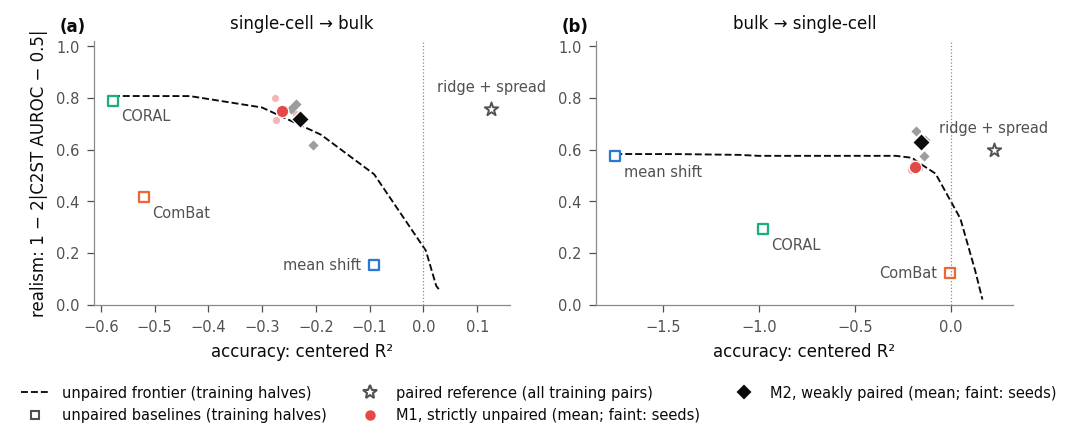

**Trained without pairs, the CycleGAN reaches the unpaired accuracy–realism frontier but does not clearly pass it; at the same realism, pairs buy accuracy.** Each panel places translations of the 135 validation sources (14 donors) by accuracy (x-axis: centered R², the R² of translated against real target profiles after removing each gene's training mean; higher is better) and realism (y-axis: 1 − 2|AUROC − 0.5|, where AUROC is that of a classifier two-sample test (C2ST) separating translated from real validation targets; 1 = indistinguishable, higher is better): (a) single-cell → bulk, (b) bulk → single-cell. Open squares are the unpaired baselines mean shift, ComBat and CORAL, fit on the same donor-disjoint training halves as the models (single-cell profiles of 33 donors, bulk profiles of 35 others). The dashed curve is the unpaired frontier: the highest realism reached at each accuracy by any blend of two of these baselines and the training-target mean, all fit on the same training halves. A model's margin is its realism minus the frontier's realism at the model's accuracy. Filled markers are the chosen strictly unpaired model (M1, red circles) and the weakly paired model (M2, black diamonds, which also uses composition networks trained on pairs), each the mean of 3 seeds, with the seeds faint. The open star is ridge + spread, a paired reference fit on all 582 training pairs. The vertical dotted line marks centered R² 0, the accuracy of predicting the training mean. M1 lies on the frontier in both directions (margin +0.023 and −0.026, at the chosen checkpoints and not averaged with neighboring evaluations), M2 slightly above it in bulk → single-cell (+0.086), and ridge + spread is as realistic as M1 at much higher accuracy (centered R² 0.126 and 0.224 against −0.263 and −0.188).

In [9]:
# Figure 3.1: the chosen models on the accuracy-realism plane, against the unpaired frontier (halving 0).
frontier = pd.read_csv(paths.results_dir(1) / "frontier_val_halves.csv")
fig, ax = figure("double", 2.8, 1, 2)
for a, d in zip(ax, tr.DIRECTIONS):
    env = envelope(frontier[(frontier.halving == 0) & (frontier.direction == d)])
    a.plot(env["r2_centered"], env["realism"], color=INK, lw=0.9, ls="--", zorder=1)
    for k, name in enumerate(("mean shift", "ComBat", "CORAL")):
        r = halves[(halves.halving == 0) & (halves.direction == d) & (halves.baseline == name)].iloc[0]
        a.scatter(r["r2_centered"], 1 - 2 * abs(r["c2st_auroc"] - 0.5), s=20, marker="s", facecolor="white", edgecolor=SERIES[k], lw=1.1, zorder=2)
        left = (d, name) in (("S->B", "mean shift"), ("B->S", "ComBat"))   # these two sit just left of the frontier: label on their left
        a.annotate(name, (r["r2_centered"], 1 - 2 * abs(r["c2st_auroc"] - 0.5)), xytext=(-6, 0) if left else (4, -4), textcoords="offset points",
                   ha="right" if left else "left", va="center" if left else "top", fontsize=7, color=INK_2)
    for name, runs, col, mk in (("M1", chosen_m1, SERIES[7], "o"), ("M2", chosen_m2, INK, "D")):
        pts = np.array([[r["best"][f"{d} r2_centered"], r["best"][f"{d} realism"]] for r in runs])
        a.scatter(*pts.T, s=12, color=col, marker=mk, alpha=0.4, lw=0, zorder=3)
        a.scatter(*pts.mean(0), s=36, color=col, marker=mk, edgecolor="white", lw=0.6, zorder=4)
    r = paired[(paired.direction == d) & (paired.baseline == "ridge + spread")].iloc[0]
    a.scatter(r["r2_centered"], 1 - 2 * abs(r["c2st_auroc"] - 0.5), s=46, marker="*", facecolor="white", edgecolor=INK_2, lw=0.9, zorder=2)
    a.annotate("ridge + spread", (r["r2_centered"], 1 - 2 * abs(r["c2st_auroc"] - 0.5)), xytext=(0, 7), textcoords="offset points", ha="center", va="bottom", fontsize=7, color=INK_2)
    a.axvline(0, color=MUTED, lw=0.6, ls=":")
    a.set(xlabel="accuracy: centered R²", ylabel="realism: 1 − 2|C2ST AUROC − 0.5|" if d == "S->B" else "", title=label(d), ylim=(0, 1.02))
    if d == "B->S":
        a.xaxis.set_major_locator(plt.MultipleLocator(0.5))
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], color=INK, lw=0.9, ls="--", label="unpaired frontier (training halves)"),
                    Line2D([], [], ls="", marker="s", mfc="white", mec=INK_2, label="unpaired baselines (training halves)"),
                    Line2D([], [], ls="", marker="*", ms=7, mfc="white", mec=INK_2, label="paired reference (all training pairs)"),
                    Line2D([], [], ls="", marker="o", color=SERIES[7], label="M1, strictly unpaired (mean; faint: seeds)"),
                    Line2D([], [], ls="", marker="D", color=INK, label="M2, weakly paired (mean; faint: seeds)")],
           loc="outside lower center", ncol=3)
panel_labels(ax)
save_show(fig, FIG, "3.1_models_vs_frontier")
show_caption("3.1_models_vs_frontier")

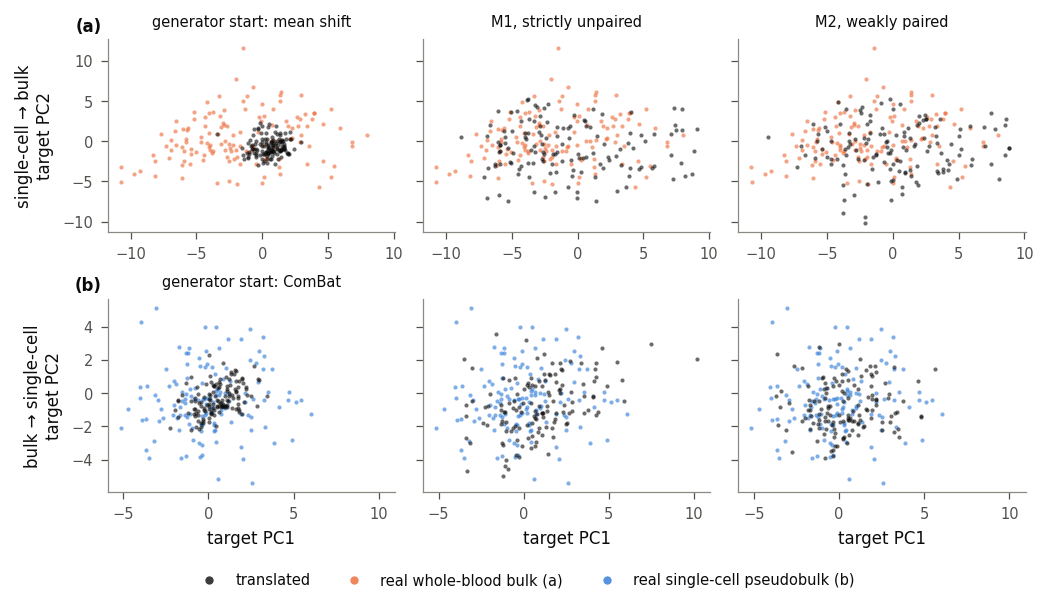

**Adversarial training spreads the translations over the real target distribution, which the baseline starts do not.** Translated (black) and real (color) validation profiles, one point per profile, 135 pairs from 14 donors, on the first two principal components (PCs) of the target domain, fit on the real training targets: (a) single-cell → bulk, with real whole-blood bulk in orange; (b) bulk → single-cell, with real single-cell pseudobulk in blue. Columns, left to right: the generator at the start of training, which equals the unpaired baseline it is initialized at (mean shift in single-cell → bulk, ComBat in bulk → single-cell, both fit on the training halves, as named above each panel); the strictly unpaired model M1; the weakly paired model M2 (seed 0 for both). The baseline starts concentrate their translations near the center of the real profiles (diversity ratio, the mean pairwise distance among translations over that among real targets, 0.612 and 0.675), and both models spread them nearly as widely as the real profiles (M1 0.900 and 0.929, M2 0.856 and 0.873); in single-cell → bulk their translations extend beyond the real profiles on the positive side of PC1.

diversity ratio (seed 0): {'single-cell → bulk, start: mean shift': 0.612, 'single-cell → bulk, M1': 0.9, 'single-cell → bulk, M2': 0.856, 'bulk → single-cell, start: ComBat': 0.675, 'bulk → single-cell, M1': 0.929, 'bulk → single-cell, M2': 0.873}


In [10]:
from scipy.spatial.distance import pdist

# Figure 3.3: translated vs real validation targets on the first two PCs of the target domain (fit on the real training targets).
fig, ax = figure("double", 3.9, 2, 3, sharex="row", sharey="row")
START = {"S->B": "mean shift", "B->S": "ComBat"}
s0 = {"M1": next(r for r in chosen_m1 if r["seed"] == 0), "M2": next(r for r in chosen_m2 if r["seed"] == 0)}
div = {}
for row, d in enumerate(tr.DIRECTIONS):
    pca, tgt_name = ctx0.ev[d].pca_, "bulk" if d == "S->B" else "single-cell"
    a0, b0 = ctx0.init[d]
    outs = {f"start: {START[d]}": np.maximum(ctx0.src[d] * a0 + b0, 0)}
    for name, r in s0.items():
        g = tr.load_generators(r["state"], P.x_sc.shape[1], r["cfg"]["hidden"])[0 if d == "S->B" else 1]
        with torch.no_grad():
            outs[name] = g(torch.as_tensor(ctx0.src[d])).numpy()
    zr = pca.transform(ctx0.tgt[d])
    for col, (name, y) in enumerate(outs.items()):
        a, zh = ax[row, col], pca.transform(y)
        div[(label(d), name)] = pdist(np.asarray(y, np.float64)).mean() / pdist(ctx0.tgt[d].astype(np.float64)).mean()   # diversity ratio, as in the evaluators
        a.scatter(*zr[:, :2].T, s=4, color=DOMAIN[tgt_name], alpha=0.6, linewidths=0, rasterized=True)
        a.scatter(*zh[:, :2].T, s=4, color=INK, alpha=0.6, linewidths=0, rasterized=True)
        if col == 0:
            a.set_title(f"generator start: {START[d]}", fontsize=7)
        elif row == 0:
            a.set_title({"M1": "M1, strictly unpaired", "M2": "M2, weakly paired"}[name], fontsize=7)
        a.set(xlabel="target PC1" if row == 1 else "", ylabel=f"{label(d)}\ntarget PC2" if col == 0 else "")
from matplotlib.lines import Line2D
dot = dict(ls="", marker="o", ms=4, mew=0, alpha=0.8)
fig.legend(handles=[Line2D([], [], color=INK, label="translated", **dot),
                    Line2D([], [], color=DOMAIN["bulk"], label=f"real {label('bulk')} (a)", **dot),
                    Line2D([], [], color=DOMAIN["single-cell"], label=f"real {label('sc')} (b)", **dot)],
           loc="outside lower center", ncol=3)
panel_labels(ax[:, 0])
save_show(fig, FIG, "3.3_translation_pca")
show_caption("3.3_translation_pca")
print("diversity ratio (seed 0):", {f"{k[0]}, {k[1]}": round(v, 3) for k, v in div.items()})


In single-cell → bulk, M1 is about as realistic as CORAL (0.750 against 0.790) at much higher accuracy (centered R² −0.263 against −0.578), but less accurate than mean shift (−0.093): it sits on the frontier, which none of the single baselines reaches (Figure 3.1). Ridge + spread, ridge regression with its outputs stretched about the training-target mean (Phase 1, §3.4), matches M1's realism (0.757) at centered R² 0.126. In bulk → single-cell it reaches centered R² 0.224 at realism 0.597, against −0.188 and 0.533 for M1. M2's bulk → single-cell realism (0.629) is the highest in Table 3.6, but its centered R² is still 0.377 below that of ridge + spread.

**Adversarial training spreads the translations over the target distribution.** The baseline starts concentrate their translations near the center of the real profiles (diversity ratio 0.612 for mean shift in single-cell → bulk and 0.675 for ComBat in bulk → single-cell, seed 0), and both GANs spread them nearly as widely as the real profiles (M1 0.900 and 0.929, M2 0.856 and 0.873; Figure 3.3). In single-cell → bulk the GANs' translations extend beyond the real profiles on the positive side of the first principal component. Both GANs also identify the true draw among a donor's draws more often than chance (within-donor top-1 rate 0.252 and 0.232 in single-cell → bulk, against chance 0.104 and mean shift's 0.193), so their translations keep some sample-specific information.

**Adversarial training costs composition and granulocyte signal, which composition supervision partly restores.** Under the marker probe, M1's composition R² falls below that of the baselines the generators start at: from 0.469 (mean shift) to 0.398 in single-cell → bulk, and from 0.333 (ComBat) to −0.067 in bulk → single-cell. M2 recovers it to 0.587 in single-cell → bulk, about ComBat's 0.570, but only to 0.206 in bulk → single-cell, below ComBat's 0.333 (Table 3.6). Composition supervision repairs M1 but does not make M2 better on composition than the simplest unpaired baseline. The ridge probe tells a more favorable story. In single-cell → bulk, composition R² under the ridge probe falls from mean shift's 0.464 to 0.288 for M1; M2 raises it to 0.670, above ridge + spread (0.609), but the marker probe does not confirm this: M2 scores 0.587 against 0.637 for ridge + spread in single-cell → bulk, and 0.206 against 0.374 in bulk → single-cell (Table 3.6). The ridge probe reads all 5,000 genes, as $C_B$ does, so the task loss can move it directly, and by the rule of Phase 2 M2's ridge-probe advantage over ridge + spread is suspect and not counted. Both GANs underestimate granulocyte gene expression more than mean shift does (granulocyte gap −0.142 for M1 and −0.110 for M2, against −0.062).

### 4.5 Training dynamics

**Training is stable, and selection picks checkpoints from a plateau around the frontier.**

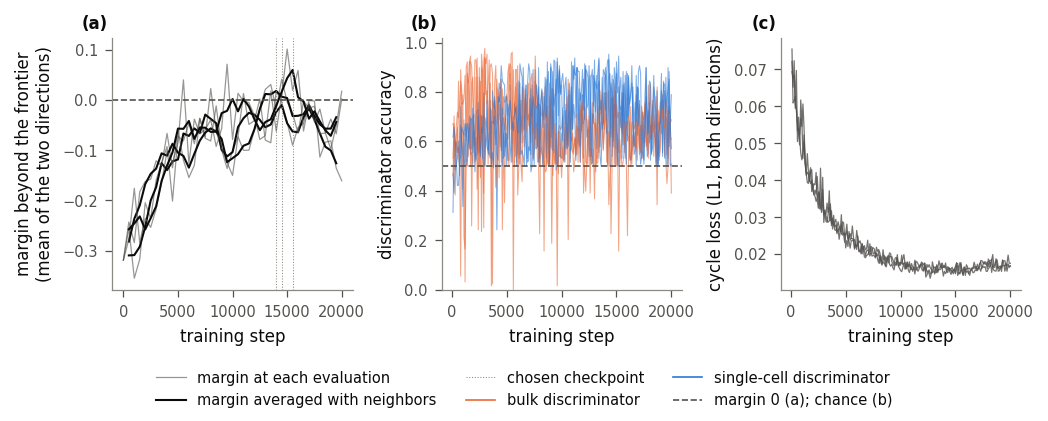

margin after step 10,000 (mean of directions): mean -0.036, range -0.161 to 0.101 | SD of the change between consecutive evaluations: mean of directions 0.062, single-cell → bulk 0.098, bulk → single-cell 0.054
chosen steps: [14000, 14500, 15500] | margin at step 0: -0.319 | cycle loss, first log: 0.072, mean after step 10,000: 0.016 | discriminator accuracy after step 10,000 (5th-95th percentile): bulk 0.50-0.78, single-cell 0.51-0.91


**Training of the chosen strictly unpaired setting is stable: the margin beyond the frontier rises to just below zero within 10,000 steps and stays there.** One line per seed (3 seeds) for the chosen setting (cycle weight 20, identity loss on, discriminator learning rate 2 × 10⁻⁴), trained for 20,000 steps on the training halves. (a) Margin beyond the unpaired frontier (realism minus the frontier's realism at the same accuracy) on the 135 validation pairs (14 donors), averaged over the two directions, at each evaluation every 500 steps (gray) and averaged with its two neighboring evaluations (black), the quantity used for checkpoint selection; dotted vertical lines mark each seed's chosen checkpoint, and the dashed horizontal line marks a margin of 0, the frontier itself. (b) Discriminator accuracy on each training batch of real and translated profiles (logged every 100 steps): orange, the bulk discriminator; blue, the single-cell discriminator; the dashed line at 0.5 is chance. (c) Cycle-consistency loss, the mean absolute difference between a profile and its round trip through both generators, summed over the two directions (not weighted by the cycle weight). The chosen checkpoints are at steps 14,000, 14,500 and 15,500; after step 10,000 the margin averages −0.036 and changes between consecutive evaluations with SD 0.062, more than the differences between the best settings.

In [11]:
# Figure 3.2: training of the chosen M1 setting: validation margin per direction over training, discriminator accuracy and cycle loss.
fig, ax = figure("double", 2.7, 1, 3)
for r in chosen_m1:
    ev, lg = pd.DataFrame(r["evals"]), pd.DataFrame(r["log"])
    ax[0].plot(ev["step"], ev["margin"], color=INK_2, lw=0.6, alpha=0.6, label="checkpoint" if r["seed"] == 0 else None)
    ax[0].plot(ev["step"], ev["margin_avg"], color=INK, lw=1.0, label="averaged with neighbors" if r["seed"] == 0 else None)
    ax[1].plot(lg["step"], lg["d_acc_bulk"], color=DOMAIN["bulk"], lw=0.5, alpha=0.6, label="bulk discriminator" if r["seed"] == 0 else None)
    ax[1].plot(lg["step"], lg["d_acc_sc"], color=DOMAIN["single-cell"], lw=0.5, alpha=0.6, label="single-cell discriminator" if r["seed"] == 0 else None)
    ax[2].plot(lg["step"], lg["cyc"], color=INK_2, lw=0.6, alpha=0.8)
    ax[0].axvline(r["best_step"], color=MUTED, lw=0.5, ls=":")
ax[0].axhline(0, **THRESHOLD)
ax[0].set(xlabel="training step", ylabel="margin beyond the frontier\n(mean of the two directions)")
ax[1].axhline(0.5, **THRESHOLD)
ax[1].set(xlabel="training step", ylabel="discriminator accuracy", ylim=(0, 1.02))
ax[2].set(xlabel="training step", ylabel="cycle loss (L1, both directions)")
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], color=INK_2, lw=0.6, alpha=0.6, label="margin at each evaluation"),
                    Line2D([], [], color=INK, lw=1.0, label="margin averaged with neighbors"),
                    Line2D([], [], color=MUTED, lw=0.5, ls=":", label="chosen checkpoint"),
                    Line2D([], [], color=DOMAIN["bulk"], lw=0.8, label="bulk discriminator"),
                    Line2D([], [], color=DOMAIN["single-cell"], lw=0.8, label="single-cell discriminator"),
                    Line2D([], [], **THRESHOLD, label="margin 0 (a); chance (b)")],
           loc="outside lower center", ncol=3)
panel_labels(ax)
save_show(fig, FIG, "3.2_m1_training")
logs = [pd.DataFrame(r["log"]) for r in chosen_m1]
late = pd.concat([lg[lg.step > 10000] for lg in logs])
late_ev = pd.concat([pd.DataFrame(r["evals"]).query("step > 10000") for r in chosen_m1])
jump = lambda col: np.concatenate([np.diff(pd.DataFrame(r["evals"]).query("step > 0")[col].to_numpy()) for r in chosen_m1]).std()
print("margin after step 10,000 (mean of directions): mean %.3f, range %.3f to %.3f | SD of the change between consecutive evaluations: mean of directions %.3f, single-cell → bulk %.3f, bulk → single-cell %.3f"
      % (late_ev.margin.mean(), late_ev.margin.min(), late_ev.margin.max(), jump("margin"), jump("S->B margin"), jump("B->S margin")))
print("chosen steps:", sorted(r["best_step"] for r in chosen_m1),
      "| margin at step 0: %.3f" % np.mean([r["evals"][0]["margin"] for r in chosen_m1]),
      "| cycle loss, first log: %.3f, mean after step 10,000: %.3f" % (np.mean([lg.cyc.iloc[0] for lg in logs]), late.cyc.mean()),
      "| discriminator accuracy after step 10,000 (5th-95th percentile): bulk %.2f-%.2f, single-cell %.2f-%.2f"
      % (*late.d_acc_bulk.quantile([0.05, 0.95]), *late.d_acc_sc.quantile([0.05, 0.95])))
show_caption("3.2_m1_training")

From the baseline starts (margin −0.319, averaged over the two directions and the 3 seeds) the margin rises to just below 0 by step 10,000 and stays there until step 20,000 (mean −0.036 after step 10,000, range −0.161 to +0.101; Figure 3.2a); the chosen checkpoints, at steps 14,000, 14,500 and 15,500, lie on this plateau. The discriminators neither win nor lose outright: after step 10,000 the 5th to 95th percentiles of their batch accuracy are 0.50 to 0.78 (bulk) and 0.51 to 0.91 (single-cell; Figure 3.2b). The cycle loss falls from 0.072 to a plateau (mean 0.016 after step 10,000; Figure 3.2c). From one evaluation to the next the margin changes with SD 0.062 (0.098 in single-cell → bulk and 0.054 in bulk → single-cell), more than the differences between the best settings.

### 4.6 Frozen models

We saved the chosen settings' generators, each seed's at its chosen checkpoint, with their hashes for the test evaluation (Phase 7), together with the same settings trained on halving 1.

In [12]:
# Freeze the chosen models: each seed's generators, with their canonical hashes and provenance in results/phase3/models.json.
MODELS.mkdir(parents=True, exist_ok=True)
registry = {}
KEY = tr.code_key()
h1_m1 = [r for r in h1_runs if r["cfg"]["lambda_task"] == 0]
h1_m2 = [r for r in h1_runs if r["cfg"]["lambda_task"] > 0]
for name, runs in (("M1", chosen_m1), ("M2", chosen_m2), ("M1_halving1", h1_m1), ("M2_halving1", h1_m2)):
    for r in runs:
        assert r["code_key"] == KEY, "a run was made with different code: re-run the grid"
        path = MODELS / f"{name}_seed{r['seed']}.pt"
        torch.save({"state": r["state"], "cfg": r["cfg"]}, path)
        assert canonical_hash(torch.load(path, weights_only=False)["state"]) == r["state_hash"]
        registry[f"{name}_seed{r['seed']}"] = {"file": path.name, "canonical_hash": r["state_hash"], "config": tr.config_name(r["cfg"]),
                                               "chosen_step": r["best_step"], "halving": r["halving"], "pairs_hash": pairs_hash(P),
                                               "genes_hash": list_hash(ctx0.genes), "code_key": KEY, "commit": info["commit"]}
(RESULTS / "models.json").write_text(json.dumps(registry, indent=1, sort_keys=True) + "\n")
print(f"froze {len(registry)} models")

froze 12 models


## 5. Conclusions

- **Without pairs, the CycleGAN reaches the unpaired accuracy–realism frontier but does not clearly pass it.** The chosen M1's validation margin is +0.056 (SD 0.041 over 3 seeds) in single-cell → bulk and −0.012 (SD 0.031) in bulk → single-cell, and both are negative without checkpoint selection (−0.023 and −0.057 over the last quarter of training). On the test donors, H1 is more likely to be "not distinguishable from the unpaired frontier" than supported.
- **M1 beats the same model trained against an uninformative discriminator:** with shuffled discriminator labels it reaches realism 0.003 and 0.046 and centered R² −1.819 and −5.847.
- **Composition supervision derived from pairs helps:** M2's composition R² under the marker probe exceeds M1's by 0.189 (95% CI 0.136–0.293) in single-cell → bulk and by 0.273 (95% CI 0.155–0.511) in bulk → single-cell on validation, at similar accuracy and realism (H2, tested on the test donors in Phase 7). The composition networks behind this had seen the training donors' pairs, so the supervision is stronger than its name suggests; Phase 5 measures what honest labels buy. Under the marker probe M1 falls below its baseline starts in both directions. M2 recovers the composition that adversarial training loses in single-cell → bulk (0.587, about ComBat's 0.570) but only partly in bulk → single-cell (0.206 against ComBat's 0.333): composition supervision repairs M1 but does not make M2 better than the simplest unpaired baseline on composition.
- **At the realism of the unpaired models, pairs buy accuracy:** ridge + spread, fit on all training pairs, is as realistic as the GANs and 0.389 and 0.412 higher in centered R² than M1 (differences of Table 3.6 values).
- **M1's bulk → single-cell margin is negative on both training halvings** (−0.012 on halving 0, −0.332 on halving 1); its single-cell → bulk margin is positive on both (+0.056 and +0.094).

**Implications.**
- The 12 frozen models (M1 and M2, 3 seeds, halvings 0 and 1) are the models tested in Phase 7. Because the chosen margins are maxima over many checkpoints and settings, some shrinkage on test is expected.
- The ablations of Phase 4 start from the chosen M1 setting. The shuffled-label control shows that an uninformative discriminator drives the generators away from the data; whether the cycle and identity losses alone keep them near the data is the question of the adversarial on/off ablation.
- The loss of granulocyte signal and of composition under adversarial training is a question for the analysis of Phase 6.


## 6. Limitations

- **Robustness of the composition gain not yet tested.** For any model trained with a composition task loss, the attack-and-transfer test of Phase 2 has to be repeated on its chosen checkpoints, to check that the generators do not exploit the composition networks. For M2 this is done in Phase 6, before H2 is reported on the test donors.
- **Validation only.** All numbers here are on 135 validation pairs from 14 donors, the same data used to choose settings and checkpoints, so they are optimistic. The confirmatory test is in Phase 7.
- **Selection and seed noise.** The selected margin is the best of about 38 evaluations in each of 12 settings, and its seed SD (0.041 and 0.031) is as large as the margin. Differences between the top settings are within one seed SD.
- **One cohort, one split of each kind.** Sound Life only; the two training halvings share 19 of 33 single-cell donors, so the sensitivity check is not a replicate.
- **The comparator is a finite family.** The frontier is built from blends of three baselines and the training mean on a grid of weights; other unpaired methods could raise it. Being a maximum over many noisy points, it is also biased upward, against the model.
- **Choices not explored:** one generator architecture, a small configuration grid (12 and 9 settings), a fixed training length, and deterministic generators (a stochastic generator is a candidate for Phase 5).


## 7. Reproducibility

Each run takes 40–101 minutes on CPU; the 70 runs (36 M1, 27 M2, 6 on halving 1 and the control) took about 17 hours with 6 workers of 4 threads each on a 24-thread Intel Core Ultra 9 275HX. Runs are deterministic on CPU at 4 threads per worker and independent of the number of workers. Each (configuration, seed, halving) run is cached in `data/processed/phase3/` under a key covering the code it depends on (`dgm/translation.py`, the paths, metrics, frontier, baselines, models, composition and data modules), the Phase 1 frontier, the Phase 2 model registry, the pairs file and the Python, PyTorch, scikit-learn, NumPy, SciPy and BLAS versions; delete the cache to recompute. The runs are executed in parallel by `dgm.grid.run_grid`, which passes each result back through the cache; with a full cache the notebook runs in minutes. The known-answer tests of §3.2 are `python -m tests.test_translation`, and the synthetic drift numbers come from `python -m scripts.phase3_synthetic_checks` (`synthetic_checks.csv`); the frozen generators are written to `data/models/phase3/`.

Outputs in `results/phase3/`:
- `m1_runs_val.csv`, `m2_runs_val.csv`: one row per run, with the chosen step, the averaged margin and the chosen checkpoint's main metrics per direction.
- `m1_grid_val.csv`, `m2_grid_val.csv`: one row per setting, all metrics averaged over seeds (Tables 3.1 and 3.3).
- `negative_control_val.csv` (Table 3.2c), `h2_val.csv` (Table 3.4), `halving_sensitivity_val.csv` (per-seed margins, Table 3.5), `models_vs_baselines_val.csv` (Table 3.6).
- `synthetic_checks.csv`: the synthetic recovery checks of §3.2 (written by the script above, not by this notebook).
- `models.json`: the frozen models' registry (file, canonical hash, configuration, chosen step, halving, data and code hashes, commit).
- `figures/`: Figures 3.1–3.3 as PNG and PDF, with their captions in `captions.md`.

## References

- Hoffman, J., Tzeng, E., Park, T., Zhu, J.-Y., Isola, P., Saenko, K., Efros, A. A. & Darrell, T. CyCADA: cycle-consistent adversarial domain adaptation. *ICML* (2018).
- Johnson, W. E., Li, C. & Rabinovic, A. Adjusting batch effects in microarray expression data using empirical Bayes methods. *Biostatistics* 8, 118–127 (2007).
- Kingma, D. P. & Ba, J. Adam: a method for stochastic optimization. *ICLR* (2015).
- Lopez-Paz, D. & Oquab, M. Revisiting classifier two-sample tests. *ICLR* (2017).
- Mao, X., Li, Q., Xie, H., Lau, R. Y. K., Wang, Z. & Smolley, S. P. Least squares generative adversarial networks. *ICCV*, 2813–2821 (2017).
- Sun, B., Feng, J. & Saenko, K. Return of frustratingly easy domain adaptation. *AAAI* (2016).
- Zhu, J.-Y., Park, T., Isola, P. & Efros, A. A. Unpaired image-to-image translation using cycle-consistent adversarial networks. *ICCV* (2017).